# Week 1: Data Acquisition, Cleaning, and Preprocessing
**Dataset:** Public Titanic passenger dataset  
**Run environment:** Google Colab

Run each cell in order. Capture screenshots of the important outputs and use the actual counts in your report.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme()

## 2. Acquire the dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
raw_df = pd.read_csv(DATA_URL)
df = raw_df.copy()

print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Source page: https://www.kaggle.com/competitions/titanic/data  
Public CSV mirror: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv

The commonly used Titanic training dataset has 891 rows and 12 columns, but verify the actual shape from your run.

## 3. Initial exploration

In [3]:
raw_df.info()
display(raw_df.describe(include="all").T)
display(raw_df.dtypes.rename("data_type").to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


,data_type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


## 4. Missing-value report

In [4]:
missing_report = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)
print("Total missing cells:", int(raw_df.isna().sum().sum()))

,missing_count,missing_percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Total missing cells: 866


## 5. Duplicate and category checks

In [5]:
print("Exact duplicate rows:", int(raw_df.duplicated().sum()))
if "PassengerId" in raw_df:
    print("Duplicate PassengerId values:", int(raw_df["PassengerId"].duplicated().sum()))

for col in ["Sex", "Embarked", "Pclass", "Survived"]:
    if col in raw_df:
        print(f"\\n{col} value counts:")
        display(raw_df[col].value_counts(dropna=False).to_frame("count"))

Exact duplicate rows: 0
Duplicate PassengerId values: 0
\nSex value counts:


,count
Sex,
male,577
female,314


\nEmbarked value counts:


,count
Embarked,
S,644
C,168
Q,77
NaN,2


\nPclass value counts:


,count
Pclass,
3,491
1,216
2,184


\nSurvived value counts:


,count
Survived,
0,549
1,342


## 6. Standardize text fields

In [6]:
df = raw_df.copy()
for col in ["Sex", "Embarked"]:
    if col in df:
        df[col] = df[col].astype("string").str.strip()
if "Sex" in df:
    df["Sex"] = df["Sex"].str.lower()
if "Embarked" in df:
    df["Embarked"] = df["Embarked"].str.upper()

for col in ["Sex", "Embarked"]:
    if col in df:
        display(df[col].value_counts(dropna=False).to_frame("count"))

,count
Sex,
male,577
female,314


,count
Embarked,
S,644
C,168
Q,77
<NA>,2


## 7. Handle missing values

In [7]:
print("Missing values before:")
display(df.isna().sum().to_frame("missing_count"))

if "Age" in df and df["Age"].isna().any():
    df["Age"] = df["Age"].fillna(df["Age"].median())

if "Embarked" in df and df["Embarked"].isna().any():
    modes = df["Embarked"].mode()
    if not modes.empty:
        df["Embarked"] = df["Embarked"].fillna(modes.iloc[0])

# Preserve whether cabin information existed, then drop the highly incomplete Cabin field.
if "Cabin" in df:
    df["CabinKnown"] = df["Cabin"].notna().astype(int)
    df = df.drop(columns=["Cabin"])

print("Missing values after selected treatments:")
display(df.isna().sum().to_frame("missing_count"))

Missing values before:


,missing_count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Missing values after selected treatments:


,missing_count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


Rationale: median imputation is a robust baseline for Age; mode imputation is simple for a small number of missing Embarked values. Cabin is highly incomplete, so this baseline drops the original column but preserves a CabinKnown indicator. Imputed values are estimates and can affect later statistics.

## 8. Remove exact duplicate rows

In [8]:
before = len(df)
df = df.drop_duplicates()
print("Exact duplicate rows removed:", before - len(df))
print("Rows after duplicate removal:", len(df))

Exact duplicate rows removed: 0
Rows after duplicate removal: 891


## 9. Check logical ranges / erroneous values

In [9]:
checks = {}
if "Survived" in df:
    checks["Survived outside {0,1}"] = int((~df["Survived"].isin([0, 1]) & df["Survived"].notna()).sum())
if "Pclass" in df:
    checks["Pclass outside {1,2,3}"] = int((~df["Pclass"].isin([1, 2, 3]) & df["Pclass"].notna()).sum())
if "Age" in df:
    checks["Negative Age"] = int((df["Age"] < 0).sum())
if "Fare" in df:
    checks["Negative Fare"] = int((df["Fare"] < 0).sum())
if {"SibSp", "Parch"}.issubset(df.columns):
    checks["Negative family counts"] = int(((df["SibSp"] < 0) | (df["Parch"] < 0)).sum())
display(pd.Series(checks, name="count").to_frame())

,count
"Survived outside {0,1}",0
"Pclass outside {1,2,3}",0
Negative Age,0
Negative Fare,0
Negative family counts,0


## 10. Detect potential outliers with IQR

In [10]:
def iqr_bounds(series):
    series = series.dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_rows = []
for col in ["Age", "Fare", "SibSp", "Parch"]:
    if col in df and pd.api.types.is_numeric_dtype(df[col]):
        low, high = iqr_bounds(df[col])
        mask = (df[col] < low) | (df[col] > high)
        outlier_rows.append({
            "column": col,
            "lower_fence": round(float(low), 3),
            "upper_fence": round(float(high), 3),
            "potential_outliers": int(mask.sum())
        })
display(pd.DataFrame(outlier_rows))

,column,lower_fence,upper_fence,potential_outliers
0,Age,2.500,54.500,66
1,Fare,-26.724,65.634,116
2,SibSp,-1.500,2.500,46
3,Parch,0.000,0.000,213


IQR fences flag unusual values; they do not prove that the values are wrong. Keep plausible extremes such as high fares unless source evidence confirms an error.

## 11. Visualize distributions

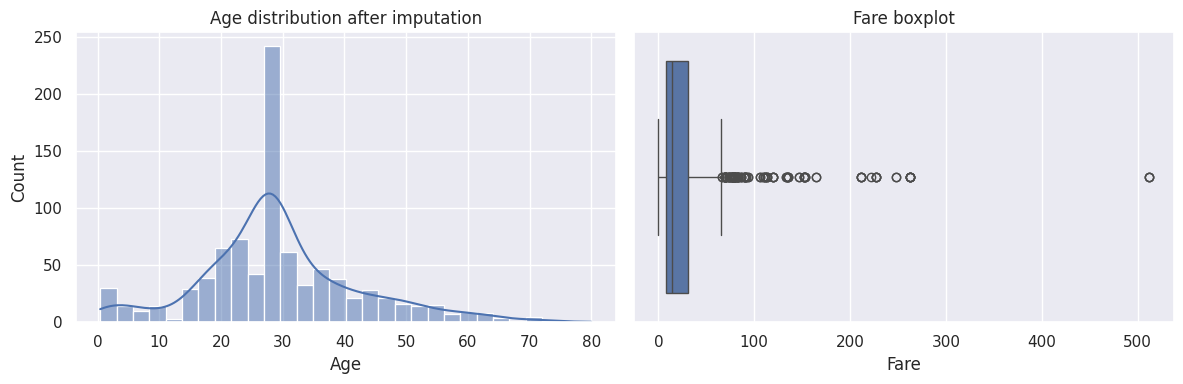

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Age", kde=True, ax=axes[0])
axes[0].set_title("Age distribution after imputation")
sns.boxplot(data=df, x="Fare", ax=axes[1])
axes[1].set_title("Fare boxplot")
plt.tight_layout()
plt.show()

## 12. Compare before and after

In [12]:
comparison = pd.DataFrame({
    "metric": ["Rows", "Columns", "Total missing cells", "Exact duplicate rows"],
    "before": [
        raw_df.shape[0], raw_df.shape[1],
        int(raw_df.isna().sum().sum()), int(raw_df.duplicated().sum())
    ],
    "after": [
        df.shape[0], df.shape[1],
        int(df.isna().sum().sum()), int(df.duplicated().sum())
    ]
})
display(comparison)
display(df.isna().sum().to_frame("remaining_missing"))

,metric,before,after
0,Rows,891,891
1,Columns,12,12
2,Total missing cells,866,0
3,Exact duplicate rows,0,0


,remaining_missing
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 13. Optional model-ready encoding

In [13]:
model_df = df.copy()
categorical_cols = [c for c in ["Sex", "Embarked"] if c in model_df.columns]
model_df = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True, dtype=int)
display(model_df.head())
print("Model-ready shape:", model_df.shape)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,CabinKnown,Sex_male,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,1,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,1,0,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,1,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,1,0,1


Model-ready shape: (891, 13)


Keep `df` as the interpretable cleaned dataset. Encoding is optional and depends on the later model. During predictive modelling, fit learned preprocessing on training data only to avoid data leakage.

## 14. Export cleaned CSV

In [14]:
output_path = Path("/content/titanic_cleaned.csv")
df.to_csv(output_path, index=False)
print("Saved:", output_path)
print("File size (bytes):", output_path.stat().st_size)

from google.colab import files
files.download(str(output_path))

Saved: /content/titanic_cleaned.csv
File size (bytes): 62876


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Conclusion and report checklist
This workflow inspected the source data, quantified missing values, standardized categories, imputed selected fields, checked duplicates and logical ranges, flagged potential outliers, visualized distributions, compared data quality, and exported a cleaned dataset.

**Capture screenshots of:** `head()`, `info()`, missing-value report before cleaning, IQR results and plots, missing-value report after cleaning, before/after comparison, and CSV export confirmation.

**References**
- Kaggle Titanic: https://www.kaggle.com/competitions/titanic/data
- CSV mirror: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv
- pandas: https://pandas.pydata.org/docs/
- NumPy: https://numpy.org/doc/
- Matplotlib: https://matplotlib.org/stable/
- Seaborn: https://seaborn.pydata.org/